# Logistiklabb 2026

**Grupp:** Rikard & David

Rapporten följer uppgifterna i *labs 2026.pdf*. För varje uppgift: modell (matematisk formulering), lösning (kod) och analys. Optimeringsproblemen (uppgift 2–5) löses med `pulp` (gratis MILP-lösare, CBC) i stället för LINGO.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 2)

---
# 1. Lagerstyrning och produktion
## 1a) Exponentiell utjämning

Prognosen uppdateras med

$$u(t) = a\,d(t) + (1-a)\,u(t-1), \qquad 0 \le a \le 1,$$

där $u(t-1)$ är prognosen för månad $t$ (gjord månaden innan) och $u(0)=50$ är startskattningen (prognos för januari). Prognosen för december är alltså $u(\text{nov})$.

Prognosfelet mäts med MAPE över de 11 månader där vi har utfall:

$$\text{MAPE} = \frac{100}{n}\sum_{t=1}^{n}\frac{|d(t)-u(t-1)|}{d(t)}\;\%.$$

In [2]:
manader = ["jan","feb","mar","apr","maj","jun","jul","aug","sep","okt","nov","dec"]
d = np.array([52, 51, 60, 46, 70, 50, 39, 48, 60, 70, 60], dtype=float)
u0 = 50.0

def utjamning(a, d=d, u0=u0):
    # Returnerar prognoserna u(t-1) för jan..dec (12 värden)
    u = [u0]
    for dt in d:
        u.append(a*dt + (1-a)*u[-1])
    return np.array(u)

def mape(a):
    u = utjamning(a)
    return 100*np.mean(np.abs(d - u[:-1]) / d)

alfa = np.round(np.arange(0, 1.01, 0.1), 1)
tabell = pd.DataFrame({
    "a": alfa,
    "Prognos dec": [utjamning(a)[-1] for a in alfa],
    "MAPE (%)": [mape(a) for a in alfa],
})
tabell

,a,Prognos dec,MAPE (%)
0,0.0,50.00,14.00
1,0.1,54.15,14.45
2,0.2,56.66,14.93
3,0.3,58.48,15.26
4,0.4,59.90,15.37
5,0.5,60.94,16.20
6,0.6,61.56,17.31
7,0.7,61.74,18.29
8,0.8,61.49,19.11
9,0.9,60.89,19.79


In [3]:
# Prognoserna månad för månad för några värden på a
prognoser = pd.DataFrame({"d(t)": list(d) + [np.nan]}, index=manader)
for a in [0.1, 0.3, 0.5, 0.9]:
    prognoser[f"u(t-1), a={a}"] = utjamning(a)
prognoser.T

,jan,feb,mar,apr,maj,jun,jul,aug,sep,okt,nov,dec
d(t),52.0,51.0,60.00,46.00,70.00,50.00,39.00,48.00,60.00,70.00,60.00,NaN
"u(t-1), a=0.1",50.0,50.2,50.28,51.25,50.73,52.65,52.39,51.05,50.74,51.67,53.50,54.15
"u(t-1), a=0.3",50.0,50.6,50.72,53.50,51.25,56.88,54.81,50.07,49.45,52.61,57.83,58.48
"u(t-1), a=0.5",50.0,51.0,51.00,55.50,50.75,60.38,55.19,47.09,47.55,53.77,61.89,60.94
"u(t-1), a=0.9",50.0,51.8,51.08,59.11,47.31,67.73,51.77,40.28,47.23,58.72,68.87,60.89


Lägst MAPE = 14.00 % vid a = 0.000, prognos dec = 50.00


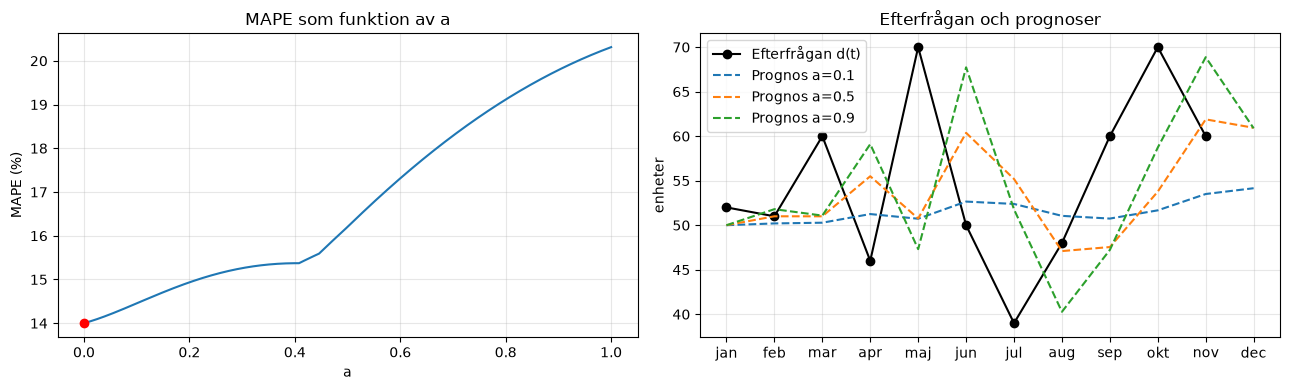

In [4]:
fin = np.linspace(0, 1, 1001)
m = np.array([mape(a) for a in fin])
a_best = fin[m.argmin()]
print(f"Lägst MAPE = {m.min():.2f} % vid a = {a_best:.3f}, prognos dec = {utjamning(a_best)[-1]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(fin, m)
ax[0].scatter([a_best], [m.min()], color="red", zorder=3)
ax[0].set(xlabel="a", ylabel="MAPE (%)", title="MAPE som funktion av a")
ax[0].grid(alpha=.3)

ax[1].plot(manader[:11], d, "ko-", label="Efterfrågan d(t)")
for a in [0.1, 0.5, 0.9]:
    ax[1].plot(manader, utjamning(a), "--", label=f"Prognos a={a}")
ax[1].set(title="Efterfrågan och prognoser", ylabel="enheter")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Analys (att fylla i / diskutera):**
- *Litet a* → prognosen lägger lite vikt vid senaste utfallet och mycket vid historiken: jämn, trög prognos som filtrerar bort slumpvariation. $a=0$ ger alltid 50.
- *Stort a* → prognosen följer senaste utfallet nära: snabb reaktion på förändringar men också på brus. $a=1$ ger "naiv prognos" $u(t)=d(t)$.
- Efterfrågan här svänger kraftigt utan tydlig trend, så … *(kommentera vilket a som gav lägst MAPE och varför)*.

### Härledning av den rekursiva formeln

Utgå från den viktade summan av hela tidsserien där vikterna avtar geometriskt:

$$u(t) = a\,d(t) + a(1-a)\,d(t-1) + a(1-a)^2 d(t-2) + \dots + (1-a)^t u(0)
= a\sum_{k=0}^{t-1}(1-a)^k d(t-k) + (1-a)^t u(0).$$

Skriv motsvarande uttryck för $u(t-1)$ och multiplicera med $(1-a)$:

$$(1-a)\,u(t-1) = a\sum_{k=0}^{t-2}(1-a)^{k+1} d(t-1-k) + (1-a)^t u(0) = a\sum_{k=1}^{t-1}(1-a)^{k} d(t-k) + (1-a)^t u(0).$$

Det är exakt alla termer i $u(t)$ utom den första, $a\,d(t)$. Alltså

$$u(t) = a\,d(t) + (1-a)\,u(t-1).$$

Vikterna $a(1-a)^k$ summerar (tillsammans med $(1-a)^t$) till 1, så det är ett riktigt viktat medelvärde där äldre observationer väger exponentiellt mindre.

## 1b) ABC-analys

Lagervärde per artikel = antal × medelkostnad. Artiklarna sorteras efter lagervärde och den kumulativa andelen beräknas. Vanlig gränsdragning (Pareto): **A** ≈ de första 80 % av värdet, **B** 80–95 %, **C** resterande 5 %.

In [5]:
abc = pd.read_excel("abc.xlsx", header=2, usecols="B:D", nrows=25)
abc.columns = ["vara", "antal", "medelkostnad"]
abc["vara"] = abc["vara"].astype(int)
abc["lagervärde"] = abc["antal"] * abc["medelkostnad"]
abc = abc.sort_values("lagervärde", ascending=False).reset_index(drop=True)
abc["andel (%)"] = 100 * abc["lagervärde"] / abc["lagervärde"].sum()
abc["kumulativ (%)"] = abc["andel (%)"].cumsum()
abc["andel artiklar (%)"] = 100 * (abc.index + 1) / len(abc)

def klass(kum_fore):
    # klassa efter kumulativ andel FÖRE artikeln, så att artikeln som passerar 80 % blir A
    return "A" if kum_fore < 80 else ("B" if kum_fore < 95 else "C")
abc["klass"] = (abc["kumulativ (%)"] - abc["andel (%)"]).apply(klass)
abc

,vara,antal,medelkostnad,lagervärde,andel (%),kumulativ (%),andel artiklar (%),klass
0,15,84000,30,2520000,39.91,39.91,4.0,A
1,19,21770,35,761950,12.07,51.98,8.0,A
2,13,1306,500,653000,10.34,62.32,12.0,A
3,3,70000,5,350000,5.54,67.87,16.0,A
4,10,19593,13,254709,4.03,71.90,20.0,A
5,1,700,342,239400,3.79,75.69,24.0,A
6,9,10500,21,220500,3.49,79.18,28.0,A
7,4,68000,3,204000,3.23,82.42,32.0,A
8,12,19593,10,195930,3.10,85.52,36.0,B
9,2,800,200,160000,2.53,88.05,40.0,B


In [6]:
sammanfattning = abc.groupby("klass").agg(
    antal_artiklar=("vara", "count"),
    lagervärde=("lagervärde", "sum"),
    andel_värde=("andel (%)", "sum"),
)
sammanfattning["andel_artiklar"] = 100 * sammanfattning["antal_artiklar"] / len(abc)
sammanfattning

,antal_artiklar,lagervärde,andel_värde,andel_artiklar
klass,,,,
A,8,5203559,82.42,32.0
B,7,868600,13.76,28.0
C,10,241672,3.83,40.0


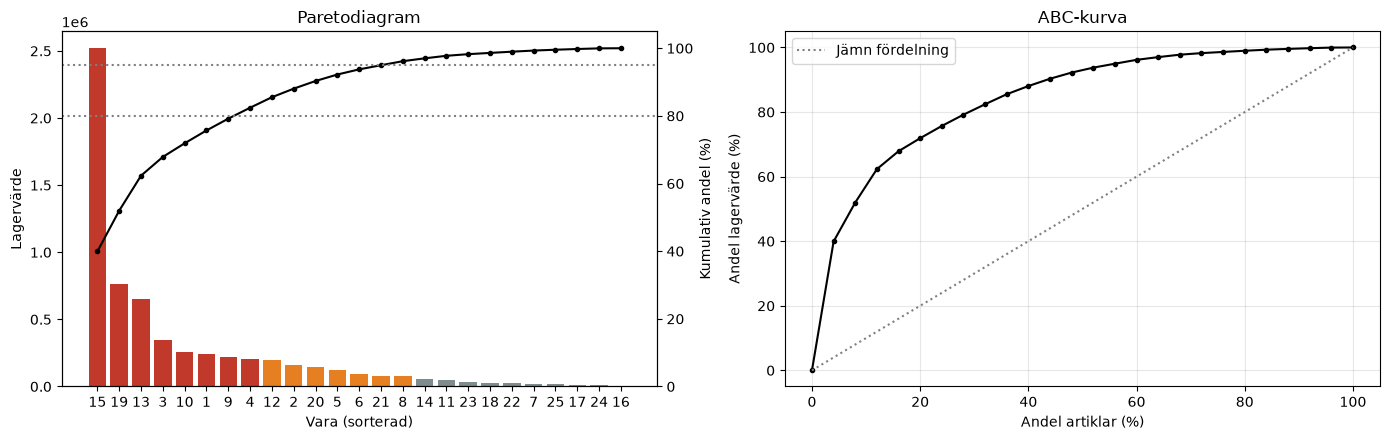

In [7]:
farg = abc["klass"].map({"A": "#c0392b", "B": "#e67e22", "C": "#7f8c8d"})
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].bar(abc["vara"].astype(str), abc["lagervärde"], color=farg)
ax[0].set(xlabel="Vara (sorterad)", ylabel="Lagervärde", title="Paretodiagram")
ax2 = ax[0].twinx()
ax2.plot(abc["vara"].astype(str), abc["kumulativ (%)"], "k.-")
ax2.axhline(80, ls=":", c="gray"); ax2.axhline(95, ls=":", c="gray")
ax2.set(ylabel="Kumulativ andel (%)", ylim=(0, 105))

ax[1].plot([0] + list(abc["andel artiklar (%)"]), [0] + list(abc["kumulativ (%)"]), "k.-")
ax[1].plot([0, 100], [0, 100], ":", c="gray", label="Jämn fördelning")
ax[1].set(xlabel="Andel artiklar (%)", ylabel="Andel lagervärde (%)", title="ABC-kurva")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Analys (att fylla i / diskutera):** Hur många A-artiklar blev det och hur stor andel av lagervärdet står de för? Vad betyder det för styrningen — A-artiklar: tät uppföljning, noggranna prognoser och beställningspunkter; C-artiklar: enkla regler, större partier, mindre kontroll.

---
# 2. Heltalsprogrammering (tilldelning av arbetsuppgifter)

### 2a) Modell och lösning

*TODO: mängder, parametrar, binära variabler $x_{ij}$, målfunktion och bivillkor.*

### 2b) Person 1 har 6 dagar

*TODO*

---
# 3. Omlastningsmodell: probabilistiska bivillkor och heltal

### 3a) Nätverk och definitioner
### 3b) Generell modell
### 3c) Lösning med medelefterfrågan
### 3d) Probabilistiska bivillkor (90 %)
### 3e) Fasta kostnader för bruken
### 3f) Kapacitet på länkarna och heltal

---
# 4. Intermodal transportplanering

### 4a) Generell modell
### 4b) En färja (2000 lastbilar/år)
### 4c) Fler färjor
### 4d) Minskad kapacitet på vägen 2–3

---
# 5. Tomma godsvagnar

### 5a) Nätverk och modelltyp
### 5b) Generell modell
### 5c) Lösning
### 5d) Med och utan trängselvillkor
### 5e) Känslighet för P